# 03 — Learning in batches: `(B, T)` sequences and *reshape*

**Chapter 2** · suggested time: 25 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_2/03_batch_learning.ipynb)

![Roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/00_roadmap.png)

In notebook 02, each example was an **isolated pair** (character → next). For a model to use **context**, we have to give it **chunks of text**. This notebook sets up the data pipeline that we will use all the way to the GPT.

**By the end of this notebook you will be able to:**
1. explain why we learn on **mini-batches** and not on the whole corpus;
2. say what `block_size` (**T**) and `batch_size` (**B**) are, and why a window of `T` characters contains `T` examples;
3. write `get_batch`;
4. explain the step `(B, T, V) → (B·T, V)` before `F.cross_entropy`, and why it does not change any value.

**Chapter notation:** **B** = batch size, **T** = context length (*block_size*), **V** = vocabulary size, **C** = number of features per token (*n_embd*).

In [1]:
# On Google Colab: fetch the course repository (corpora + shared modules such as minigpt.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_2

In [2]:
# Setup: imports and the chapter's shared module
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # the file minigpt.py, next to this notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

CORPUS = "shakespeare" # "kaamelott" / "plato"
text, tok, train_data, val_data = minigpt.prepare_data(CORPUS)
V = tok.vocab_size

PyTorch 2.15.0+cu132 | device: cuda


## 1. Why mini-batches?

We could compute the loss on the **whole** corpus at each step (this is what chapter 1 did with the names). Three reasons not to:

1. **Memory.** For the GPT, each character produces activations of size `C` in every layer. Over 1 M characters, this does not fit in memory.
2. **Speed.** A gradient estimated on a few thousand characters is **almost as good** as an exact gradient, and costs hundreds of times less. Many small approximate steps are better than a few large exact ones.
3. **Parallelism.** Processors (and especially GPUs) efficiently compute **several examples at once** in the form of tensors.

The price to pay: the loss of a batch is a **noisy estimate**. Let's measure this noise with an already trained bigram.

loss over the WHOLE training corpus: 2.494


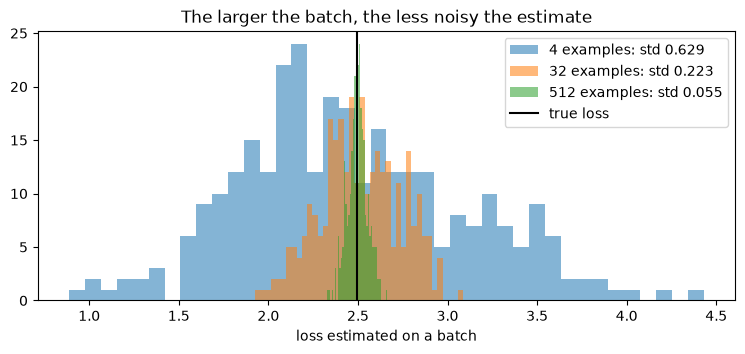

In [3]:
# A quickly trained bigram (same code as in notebook 02, minigpt version)
torch.manual_seed(1337)
table = nn.Embedding(V, V)
opt = torch.optim.AdamW(table.parameters(), lr=0.1)
for _ in range(300):
    ix = torch.randint(len(train_data) - 1, (256,))
    loss = F.cross_entropy(table(train_data[ix]), train_data[ix + 1])
    opt.zero_grad(); loss.backward(); opt.step()

with torch.no_grad():
    true_loss = F.cross_entropy(table(train_data[:-1]), train_data[1:]).item()
    print(f"loss over the WHOLE training corpus: {true_loss:.3f}")
    fig, ax = plt.subplots(figsize=(9, 3.5))
    for n in [4, 32, 512]:
        estimates = []
        for _ in range(300):
            ix = torch.randint(len(train_data) - 1, (n,))
            estimates.append(F.cross_entropy(table(train_data[ix]), train_data[ix + 1]).item())
        estimates = torch.tensor(estimates)
        ax.hist(estimates, bins=40, alpha=.55, label=f"{n} examples: std {estimates.std():.3f}")
    ax.axvline(true_loss, color="black", label="true loss")
    ax.set_xlabel("loss estimated on a batch"); ax.legend(); ax.set_title("The larger the batch, the less noisy the estimate")
    plt.show()

The standard deviation decreases roughly as $1/\sqrt{\text{batch size}}$: multiplying the batch by 16 divides the noise by 4. In practice, we pick the largest batch that fits in memory and stays fast.

---
## 2. From pairs to context windows

Instead of pairs, we cut the text into **windows** of `block_size = T` characters. The input `x` and the target `y` are **shifted by one**:

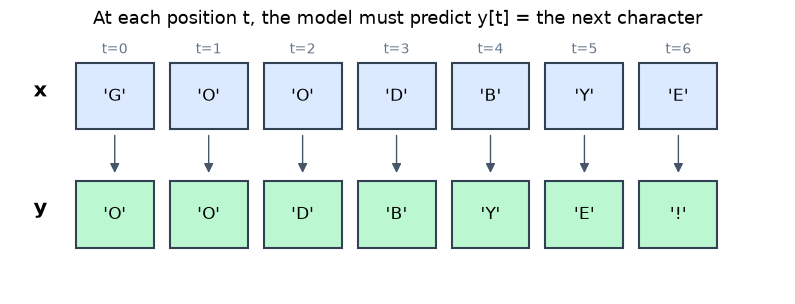

In [4]:
# One sequence provides several prediction examples.
# Change the sentence and watch how x and y shift.
from matplotlib.patches import Rectangle, FancyArrowPatch

sentence = "GOODBYE!"                  # 8 characters: 7 examples
x_vis, y_vis = sentence[:-1], sentence[1:]
T_vis = len(x_vis)
fig, ax = plt.subplots(figsize=(max(10, T_vis * 1.25), 3.4))
ax.set_xlim(-0.7, T_vis + 0.55); ax.set_ylim(-0.4, 2.7); ax.axis("off")
for t in range(T_vis):
    for y0, char, bg in [(1.55, x_vis[t], "#dbeafe"), (0.15, y_vis[t], "#bbf7d0")]:
        ax.add_patch(Rectangle((t, y0), .83, .79, facecolor=bg, edgecolor="#334155", lw=1.5))
        ax.text(t + .415, y0 + .39, repr(char), ha="center", va="center", fontsize=12)
    ax.text(t + .415, 2.45, f"t={t}", ha="center", fontsize=10, color="#64748b")
    ax.add_patch(FancyArrowPatch((t + .415, 1.51), (t + .415, 1.0), arrowstyle="-|>", mutation_scale=14, color="#475569"))
ax.text(-.3, 1.94, "x", fontsize=15, fontweight="bold", ha="right")
ax.text(-.3, .55, "y", fontsize=15, fontweight="bold", ha="right")
ax.set_title("At each position t, the model must predict y[t] = the next character", fontsize=13)
plt.show()

**A window of `T` characters contains `T` exercises**, of increasing difficulty:

In [5]:
block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for t in range(block_size):
    context, target = x[:t + 1], y[t]
    print(f"context {tok.decode(context)!r:14s} -> target {tok.itos[target.item()]!r}")

context 'F'            -> target 'i'
context 'Fi'           -> target 'r'
context 'Fir'          -> target 's'
context 'Firs'         -> target 't'
context 'First'        -> target ' '
context 'First '       -> target 'C'
context 'First C'      -> target 'i'
context 'First Ci'     -> target 't'


Two important remarks for what follows:

- **The context ranges from 1 to T characters.** So the model also learns to predict with little context, which is essential to start a generation from a single character.
- **Position `t` must only see `x[:t+1]`.** If it could read `x[t+1]`, it would be reading… the answer `y[t]`. The **causal mask** in notebook 05 will enforce this rule.

---
## 3. `get_batch`: B randomly drawn windows

![A batch](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/03_batch.png)

We draw `B` random starting positions and **stack** the windows with `torch.stack`. The result is a `(B, T)` tensor of indices. Each row is an independent excerpt: **the rows of a batch never communicate with each other**.

In [6]:
def get_batch(data, batch_size, block_size, device="cpu"):
    """Draws batch_size windows of block_size characters; y = x shifted by one."""
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i + block_size] for i in ix])
    y = torch.stack([data[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)


torch.manual_seed(1337)
xb, yb = get_batch(train_data, batch_size=4, block_size=8)
print("xb:", tuple(xb.shape), "| yb:", tuple(yb.shape))
for b in range(4):
    print(f"b={b}  x = {tok.decode(xb[b])!r:14s}  y = {tok.decode(yb[b])!r}")
print(f"\n4 × 8 = {xb.numel()} predictions to make in this batch")

xb: (4, 8) | yb: (4, 8)
b=0  x = "Let's he"      y = "et's hea"
b=1  x = 'for that'      y = 'or that '
b=2  x = 'nt that '      y = 't that h'
b=3  x = 'MEO:\nI p'     y = 'EO:\nI pa'

4 × 8 = 32 predictions to make in this batch


**Question:** why `torch.randint(len(data) - block_size, ...)` and not `len(data)`? *(Hint: what would `y` be if the window started on the last character?)*

---
## 4. The problem: `F.cross_entropy` does not accept `(B, T, V)`

Let's give this batch to the bigram from notebook 02. The table reads **one row per index**: from `(B, T)` indices, it produces `(B, T, V)` logits. But `F.cross_entropy` expects `(N, V)` and `(N,)`:

In [7]:
logits = table(xb)
print("logits:", tuple(logits.shape), "| targets:", tuple(yb.shape))
try:
    F.cross_entropy(logits, yb)
except Exception as e:
    print("ERROR:", type(e).__name__, "-", str(e)[:150])

logits: (4, 8, 65) | targets: (4, 8)


ERROR: RuntimeError - Expected target size [4, 65], got [4, 8]


With a 3-dimensional tensor, PyTorch interprets **dimension 1** as the class dimension: it thinks `T` is the number of classes. So we have to put **each prediction back on its own row**.

## 5. The *reshape*: same values, different layout

![Reshaping the logits and targets](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/03_reshape.png)

We **merge the first two dimensions**:

- logits: `(B, T, V)` → `(B·T, V)`: one row = the `V` scores of **one** position of **one** sequence;
- targets: `(B, T)` → `(B·T,)`: one element = the correct answer for that same position.

Cell `(b, t)` becomes row `b·T + t`, **for the logits as well as the targets**: the prediction ↔ answer pairing is preserved. The *reshape* does **no sum, no mean, no permutation**: it only changes how the same numbers in memory are indexed.

**Question:** in which row of the `(6, 4)` matrix do we find the scores for `b = 1`, `t = 2`? *(Answer: `1 × 3 + 2 = 5`.)*

Let's apply it to the real batch and check that the resulting loss is indeed the **mean of the `B·T` individual losses**.

In [8]:
B, T, V_ = logits.shape
loss = F.cross_entropy(logits.view(B * T, V_), yb.view(B * T))
print("logits.view:", (B * T, V_), "| targets.view:", (B * T,))
print(f"batch loss = {loss.item():.4f}")

# The same thing position by position, with two loops:
losses = [F.cross_entropy(logits[b, t:t + 1], yb[b, t:t + 1]).item() for b in range(B) for t in range(T)]
print(f"mean of the {len(losses)} individual losses = {sum(losses) / len(losses):.4f}")

# Another way to write it: put V in dimension 1, as PyTorch expects for sequences
loss_alt = F.cross_entropy(logits.transpose(1, 2), yb)     # (B, V, T) and (B, T)
print(f"variant (B, V, T)                 = {loss_alt.item():.4f}")

logits.view: (32, 65) | targets.view: (32,)
batch loss = 1.9867
mean of the 32 individual losses = 1.9867


variant (B, V, T)                 = 1.9867


> **`view` or `reshape`?** `view` never copies the data: it requires it to be laid out contiguously in memory (which is the case here). `reshape` does a `view` when possible, and a copy otherwise. Karpathy uses `view`; both give the same result here.

---
## 6. The bigram, "sequence version"

Here is the final version of the bigram, the one in `minigpt.py`. Two changes compared with notebook 02:

1. `forward` accepts `(B, T)` and does the *reshape* before the loss;
2. `generate` works on a sequence that **grows**: we compute the logits for all positions, but only keep those of the **last** one (`logits[:, -1, :]`), because it is the one that predicts the next character.

For a bigram, recomputing all positions is wasteful (only the last one matters). But this code is **already the GPT's**: once the model uses context, the last position will depend on all the previous ones.

In [9]:
class BigramLanguageModel(nn.Module):
    """The bigram: a (V, V) table that directly holds the logits."""

    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)          # (B, T, V)
        loss = None
        if targets is not None:
            B, T, V = logits.shape
            loss = F.cross_entropy(logits.view(B * T, V), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            logits = logits[:, -1, :]                     # last position
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx


torch.manual_seed(1337)
bigram = BigramLanguageModel(V)
opt = torch.optim.AdamW(bigram.parameters(), lr=0.1)
for step in range(120):
    xb, yb = get_batch(train_data, batch_size=32, block_size=8)   # 256 predictions per step
    _, loss = bigram(xb, yb)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
print(f"loss after 120 steps: {loss.item():.3f}")

start = torch.full((1, 1), tok.stoi["\n"], dtype=torch.long)    # (B=1, T=1)
print(tok.decode(bigram.generate(start, max_new_tokens=120)[0]))

loss after 120 steps: 2.597


THeor we nt mere Be quldis han'd wi. hankyorimoroushos


YORI is mpen hefigore
Crortsat at lioupiveaeth vor'th h go.LO:


Same result as in notebook 02: the only thing that changed is the **shape** of the data. With `B = 32` and `T = 8`, each step uses 256 predictions, like the 256 pairs of notebook 02.

## Summary

- We learn on **mini-batches**: an approximate but cheap gradient; the noise decreases as $1/\sqrt{B}$.
- A window of `T` characters gives **`T` exercises** (context from 1 to `T` characters); `y` is `x` shifted by one.
- `get_batch` returns `x, y` of shape `(B, T)`; the `B` rows are **independent**.
- The model produces `(B, T, V)`; `F.cross_entropy` wants `(N, V)` and `(N,)` → `logits.view(B*T, V)` and `targets.view(B*T)`. **No value changes**, cell `(b, t)` becomes row `b·T + t`.
- `generate` only keeps `logits[:, -1, :]`: the last position predicts what comes next.

**Check your understanding**
1. How many predictions does a batch with `B = 16`, `T = 64` contain?
2. What would happen if we flattened the logits to `(B·T, V)` but the targets **after transposing** them to `(T, B)`?
3. Why must the `B` sequences of a batch not "see" each other?

**Next → 04:** we have all the tools (data, loss, optimizer). What is missing is a model that exploits the context. Let's first look at **the map**: the Transformer architecture.

### References
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) and its code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture) (section "data loader: batches of chunks of data").
- I. Goodfellow, Y. Bengio, A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), MIT Press 2016, §8.1.3 *Batch and Minibatch Algorithms*.
- PyTorch documentation: [`Tensor.view`](https://pytorch.org/docs/stable/generated/torch.Tensor.view.html), [`torch.stack`](https://pytorch.org/docs/stable/generated/torch.stack.html).